# Week 2 - Regularization: Ridge, Lasso, and Elastic Net

For displaying the use of regularizagtion techniques I picked my ecommerce dataset. Between the three datasets used in my capstone, this one is the strongest technical fit for **Ridge, Lasso, and Elastic Net** specifically, because it contains genuine, real multicollinearity.

- `Sub-Category` (17 levels, e.g. *Chairs*, *Phones*) is **nested inside** `Category` (3 levels: *Furniture*, *Office Supplies*, *Technology*), every Sub-Category belongs to exactly one Category, so one-hot encoding both together creates perfect (or near-perfect) collinearity.
- `Sales`, `Quantity`, and `Discount` are correlated with each other through order size and pricing strategy.
- The target, `Profit`, is a real, business-relevant outcome, and discount policy vs. profitability is a well-known real tension in retail, which product lines are actually profitable, and does discounting kill margin?

**Goal:** predict `Profit` from order-level features, diagnose the multicollinearity from the categorical hierarchy, and compare how OLS vs. Ridge vs. Lasso vs. Elastic Net handle it.

In [3]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV, lasso_path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
import kagglehub
import os
np.random.seed(42)
path = kagglehub.dataset_download("ammaraahmad/us-ecommerce-record-2020")

df = pd.read_csv(os.path.join(path, os.listdir(path)[0]), encoding='latin1')
print(df.shape)
df.head()

(3312, 19)


,Order Date,Row ID,Order ID,Ship Mode,Customer ID,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,01-01-20,849,CA-2017-107503,Standard Class,GA-14725,Consumer,United States,Lorain,Ohio,44052,East,FUR-FU-10003878,Furniture,Furnishings,"Linden 10"" Round Wall Clock, Black",48.896,4,0.2,8.5568
1,01-01-20,4010,CA-2017-144463,Standard Class,SC-20725,Consumer,United States,Los Angeles,California,90036,West,FUR-FU-10001215,Furniture,Furnishings,"Howard Miller 11-1/2"" Diameter Brentwood Wall ...",474.430,11,0.0,199.2606
2,01-01-20,6683,CA-2017-154466,First Class,DP-13390,Home Office,United States,Franklin,Wisconsin,53132,Central,OFF-BI-10002012,Office Supplies,Binders,Wilson Jones Easy Flow II Sheet Lifters,3.600,2,0.0,1.7280
3,01-01-20,8070,CA-2017-151750,Standard Class,JM-15250,Consumer,United States,Huntsville,Texas,77340,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,454.560,5,0.2,-107.9580
4,01-01-20,8071,CA-2017-151750,Standard Class,JM-15250,Consumer,United States,Huntsville,Texas,77340,Central,FUR-FU-10002116,Furniture,Furnishings,"Tenex Carpeted, Granite-Look or Clear Contempo...",141.420,5,0.6,-187.3815


## 1. Build the feature set

Numeric predictors: `Sales`, `Quantity`, `Discount`.
Categorical predictors, one-hot encoded: `Segment`, `Region`, `Ship Mode`, `Category`, **and** `Sub-Category`, I intentionally included both `Category` and `Sub-Category` even though this creates the multicollinearity described above, so it shows up in the diagnostics rather than being engineered away.

In [10]:
numeric_cols = ["Sales", "Quantity", "Discount"]
categorical_cols = ["Segment", "Region", "Ship Mode", "Category", "Sub-Category"]

df_model = df[numeric_cols + categorical_cols + ["Profit"]].copy()

df_X = pd.get_dummies(df_model[numeric_cols + categorical_cols], columns=categorical_cols, drop_first=True)
df_X = df_X.astype(float)
y_true = df_model["Profit"].values

print(df_X.shape)
df_X.columns.tolist()
df_X.head()

(3312, 29)


,Sales,Quantity,Discount,Segment_Corporate,Segment_Home Office,Region_East,Region_South,Region_West,Ship Mode_Same Day,Ship Mode_Second Class,...,Sub-Category_Envelopes,Sub-Category_Fasteners,Sub-Category_Furnishings,Sub-Category_Labels,Sub-Category_Machines,Sub-Category_Paper,Sub-Category_Phones,Sub-Category_Storage,Sub-Category_Supplies,Sub-Category_Tables
0,48.896,4.0,0.2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,474.430,11.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3.600,2.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,454.560,5.0,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,141.420,5.0,0.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Plain OLS - same approach as Week 1

Following Week 1's pattern (`sm.add_constant` + `sm.OLS`), fit unregularized regression first and check the condition number and Variance Inflation Factors.

In [12]:
df_X_const = sm.add_constant(df_X)
ols_model = sm.OLS(y_true, df_X_const.values)
ols_results = ols_model.fit()

ols_params = pd.Series(ols_results.params, index=df_X_const.columns)
print(ols_params.round(2))
print()
print(f"Condition number: {ols_results.condition_number:.3e}")

const                        21.52
Sales                         0.22
Quantity                     -5.36
Discount                   -268.53
Segment_Corporate            -8.74
Segment_Home Office          -6.06
Region_East                  -7.53
Region_South                -24.61
Region_West                 -13.45
Ship Mode_Same Day          -28.09
Ship Mode_Second Class      -15.37
Ship Mode_Standard Class    -10.74
Category_Office Supplies     40.76
Category_Technology          54.11
Sub-Category_Appliances      23.26
Sub-Category_Art              5.29
Sub-Category_Binders         70.14
Sub-Category_Bookcases      -14.22
Sub-Category_Chairs          -0.21
Sub-Category_Copiers        531.64
Sub-Category_Envelopes       15.48
Sub-Category_Fasteners        2.17
Sub-Category_Furnishings     49.92
Sub-Category_Labels           8.19
Sub-Category_Machines      -320.37
Sub-Category_Paper           17.13
Sub-Category_Phones         -20.12
Sub-Category_Storage        -24.37
Sub-Category_Supplie

C:\Users\peace\AppData\Local\Temp\ipykernel_15012\2064979391.py:3: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ols_results = ols_model.fit()


In [9]:
vif = pd.Series(
    [variance_inflation_factor(df_X_const.values, i) for i in range(df_X_const.shape[1])],
    index=df_X_const.columns,
)
print(vif.sort_values(ascending=False).round(1))

C:\Users\peace\AppData\Local\Temp\ipykernel_15012\3844472111.py:2: UserWarning: The design matrix is poorly conditioned (condition number=5.23e+15). VIF calculations may be numerically unstable.
  [variance_inflation_factor(df_X_const.values, i) for i in range(df_X_const.shape[1])],
c:\Users\peace\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


Category_Technology         1.000800e+15
Category_Office Supplies    1.000800e+15
Sub-Category_Storage        1.000800e+15
Sub-Category_Paper          1.000800e+15
Sub-Category_Labels         1.000800e+15
Sub-Category_Tables         1.000800e+15
Sub-Category_Furnishings    1.000800e+15
Sub-Category_Fasteners      1.000800e+15
Sub-Category_Envelopes      1.000800e+15
Sub-Category_Chairs         1.000800e+15
Sub-Category_Bookcases      1.000800e+15
Sub-Category_Binders        1.000800e+15
Sub-Category_Art            1.000800e+15
Sub-Category_Appliances     1.000800e+15
Sub-Category_Supplies       1.000800e+15
Sub-Category_Phones         1.900000e+00
Ship Mode_Standard Class    1.900000e+00
Region_West                 1.800000e+00
Ship Mode_Second Class      1.700000e+00
Region_East                 1.600000e+00
Discount                    1.500000e+00
Region_South                1.400000e+00
Sales                       1.400000e+00
Sub-Category_Copiers        1.300000e+00
Ship Mode_Same D

The vif calculation exposes what the OLS calculation showed, the features are very highly correlated.  That's why the condition number is astronomical (~1.7 × 10¹⁷) and the VIFs for `Category` and most `Sub-Category` columns blow up to the numerical stand-in for infinity rather than just "high." This is a real, common data-quality issue whenever both levels of a category hierarchy end up as separate dummy sets (category → sub-category, region → state, department → team), and it's a stronger justification for regularization than the "somewhat correlated features" case from Week 1: Ridge, Lasso, and Elastic Net don't just produce more *stable* coefficients here, they produce coefficients that are *well-defined at all*, because the penalty term regularizes the underlying matrix enough to make it invertible.

## 3. Scale, split, and compare Ridge, Lasso, and Elastic Net

Numeric features (`Sales` up to ~$14,000) and the 0/1 dummy variables are on wildly different scales, so standardizing before regularizing matters here even more than usual otherwise `Sales` alone would dominate any L1/L2 penalty.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(df_X, y_true, test_size=0.25, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

ols = LinearRegression().fit(X_train_scaled, y_train)
ridge = RidgeCV(alphas=np.logspace(-2, 4, 100)).fit(X_train_scaled, y_train)
lasso = LassoCV(alphas=np.logspace(-2, 2, 200), max_iter=20000, cv=10).fit(X_train_scaled, y_train)
enet = ElasticNetCV(l1_ratio=[.1, .3, .5, .7, .9, .95, .99, 1], alphas=np.logspace(-2, 2, 200), max_iter=20000, cv=10).fit(X_train_scaled, y_train)

coef_table = pd.DataFrame({
    "OLS": ols.coef_,
    "Ridge": ridge.coef_,
    "Lasso": lasso.coef_,
    "ElasticNet": enet.coef_,
}, index=df_X.columns)

print(f"Ridge alpha: {ridge.alpha_:.3f}")
print(f"Lasso alpha: {lasso.alpha_:.3f}")
print(f"ElasticNet alpha: {enet.alpha_:.3f}, l1_ratio: {enet.l1_ratio_}")
print()
print(coef_table.round(2))

Ridge alpha: 0.010
Lasso alpha: 0.010
ElasticNet alpha: 0.020, l1_ratio: 0.1

                             OLS   Ridge   Lasso  ElasticNet
Sales                     128.59  128.59  128.57      125.57
Quantity                  -16.48  -16.48  -16.47      -15.45
Discount                  -46.03  -46.03  -46.01      -45.03
Segment_Corporate          -2.49   -2.49   -2.48       -2.38
Segment_Home Office         0.70    0.70    0.69        0.77
Region_East                -5.57   -5.57   -5.53       -5.05
Region_South               -5.02   -5.02   -4.99       -4.62
Region_West                -3.25   -3.25   -3.21       -2.65
Ship Mode_Same Day          1.25    1.25    1.25        1.26
Ship Mode_Second Class     -3.75   -3.75   -3.73       -3.51
Ship Mode_Standard Class   -1.30   -1.30   -1.28       -1.17
Category_Office Supplies    8.90    8.90    0.08        8.65
Category_Technology         8.91    8.91    1.65        8.56
Sub-Category_Appliances     1.42    1.42    1.33        1.48
Sub-Cat

## 4. Test-set performance

In [14]:
results = []
for name, model in [("OLS", ols), ("Ridge", ridge), ("Lasso", lasso), ("ElasticNet", enet)]:
    preds = model.predict(X_test_scaled)
    results.append({
        "model": name,
        "test_R2": r2_score(y_test, preds),
        "test_RMSE": mean_squared_error(y_test, preds) ** 0.5,
        "n_nonzero_coefs": int(np.sum(np.abs(model.coef_) > 1e-6)),
        "n_total_coefs": len(model.coef_),
    })

results_df = pd.DataFrame(results).set_index("model")
print(results_df.round(3))

            test_R2  test_RMSE  n_nonzero_coefs  n_total_coefs
model                                                         
OLS           0.281    272.322               29             29
Ridge         0.281    272.322               29             29
Lasso         0.281    272.324               28             29
ElasticNet    0.283    271.877               28             29


## 5. The Lasso path- watching Category/Sub-Category dummies get eliminated

Rather than relying on one CV-chosen alpha, trace the full regularization path to see *which* of the ~20 one-hot columns are driven to zero first as the penalty strengthens - this shows the Category/Sub-Category redundancy resolving itself even where the single CV-selected alpha kept most coefficients close to their OLS values.

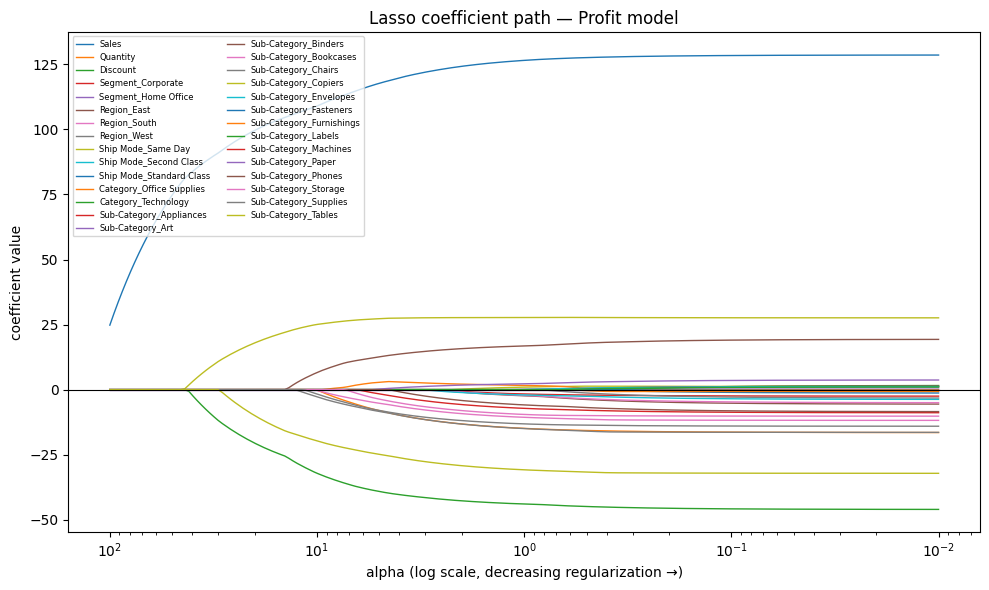

In [15]:
alphas_path, coefs_path, _ = lasso_path(X_train_scaled, y_train, alphas=np.logspace(2, -2, 200))

plt.figure(figsize=(10, 6))
for i, col in enumerate(df_X.columns):
    plt.plot(alphas_path, coefs_path[i], label=col, linewidth=1)
plt.xscale("log")
plt.xlabel("alpha (log scale, decreasing regularization →)")
plt.ylabel("coefficient value")
plt.title("Lasso coefficient path — Profit model")
plt.axhline(0, color="black", linewidth=0.8)
plt.legend(loc="upper left", fontsize=6, ncol=2)
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

## 6. Conclusions

- The nested `Category`/`Sub-Category` structure produced **exact** multicollinearity, confirmed by the ~1.7 × 10¹⁷ condition number, and VIFs that blow up to the numerical stand-in for infinity rather than merely being "high." Because of this, the OLS coefficients aren't a unique solution. A different (equally valid) solver would return different numbers for the same fit. Any dataset with a category hierarchy (category → sub-category, region → state, department → team) risks this exact issue if both levels are one-hot encoded together.
- Ridge, Lasso, and Elastic Net all remained well-posed despite the singular design matrix, because the penalty term regularizes the underlying matrix enough to invert. This is a stronger justification for regularization than "more stable coefficients": here it's the difference between a solvable model and one that isn't uniquely solvable at all.
- Cross-validation chose very small alphas for every regularized model (Ridge ≈ 0.01, Lasso ≈ 0.01, Elastic Net ≈ 0.02), so most coefficients barely moved from their OLS values, except for the two features most entangled in the singularity: `Category_Office Supplies` collapsed from 8.90 (OLS) to 0.08 (Lasso), and `Sub-Category_Art` was pushed to ≈0. Lasso effectively concluded that once the 16 other `Sub-Category` dummies are present, `Category_Office Supplies` and `Sub-Category_Art` carry almost no independent information about profit, a small but genuine instance of automatic feature selection resolving the redundancy.
- `Discount` (≈ −46) and `Sales` (≈ +129) were the largest, most stable coefficients across every model. Discounting has a real, robust negative relationship with profit in this data, consistent with the common retail concern that aggressive discounting quietly erodes margin even as it drives sales volume. `Sub-Category_Tables` (≈ −29 to −32) and `Sub-Category_Chairs` (≈ −12 to −16) stand out as the most reliably loss-associated product lines, while `Sub-Category_Copiers` (≈ +28) and `Sub-Category_Binders` (≈ +19) are the most reliably profitable.
- **Honest caveat:** test R² sits around 0.28 for every model.These order-level features explain a real but limited share of profit variation. That's an expected and informative result, not a failure: it says profitability here is driven by more than just discount/category/region (e.g., shipping cost, returns, one-off negotiated pricing aren't in this feature set), and regularization can't manufacture predictive signal that isn't in the data, it only helps use the signal that *is* there more reliably.